# Droplet Bessel beam metalens (DBBM)

200 µm aperture: amplitude/phase design → separate LCP/RCP propagation → merged PSF.
Run all cells in order. CPU only; no external data or GPU required.

## 1. Parameters
All calculations use metres. The two inward annuli have outer diameters 200 and 100 µm,
with a common 5 µm radial width. These are illustrative parameters, not an optimization.


In [7]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from lib.phase import droplet_fields
from lib.asm import angular_spectrum_method, axial_intensity

um = 1e-6
diameter = 200 * um
wavelength = 633e-9
na = 0.3
ring_ratio = 0.5
thickness = 5 * um
# Thin-ring intensity J0²: FWHM ≈ 0.358 λ/NA (narrower than an Airy spot).
expected_fwhm = 0.358 * wavelength / na
samples_per_fwhm = 3
target_dx = expected_fwhm / samples_per_fwhm
n = int(32 * np.ceil(diameter / target_dx / 32))  # Round up for FFT efficiency.
dx = diameter / n
padding = n // 2  # 2× field width reduces FFT wraparound.
x = (np.arange(n) - n // 2) * dx
amplitude, phases, fields, focal_length = droplet_fields(
    x, diameter, wavelength, na, ring_ratio, thickness)
images = Path('images')
images.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print(f'Diameter: {diameter / um:.0f} µm | λ: {wavelength / 1e-9:.0f} nm | NA: {na}')
print(f'f: {focal_length / um:.3f} µm | dx: {dx / um:.4f} µm | grid: {n}²')
print(f'Expected ring FWHM: {expected_fwhm / um:.3f} µm | samples/FWHM: {expected_fwhm / dx:.3f}')
print(f'Padded grid: {n + 2 * padding}² | ring width: {thickness / um:.1f} µm')


Diameter: 200 µm | λ: 633 nm | NA: 0.3
f: 317.980 µm | dx: 0.2500 µm | grid: 800²
Expected ring FWHM: 0.755 µm | samples/FWHM: 3.022
Padded grid: 1600² | ring width: 5.0 µm


## 2. Amplitude and phase design

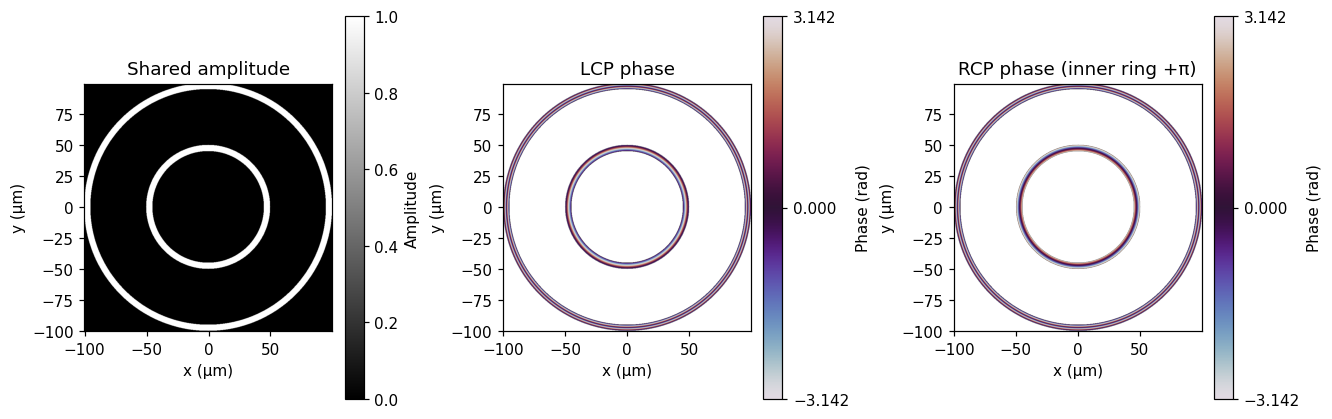

In [8]:
extent = [(x[0] - dx / 2) / um, (x[-1] + dx / 2) / um] * 2
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), constrained_layout=True)
im = axes[0].imshow(amplitude, origin='lower', extent=extent, vmin=0, vmax=1, cmap='gray')
axes[0].set_title('Shared amplitude')
fig.colorbar(im, ax=axes[0], label='Amplitude')
for ax, phase, title in zip(axes[1:], phases, ['LCP phase', 'RCP phase (inner ring +π)']):
    wrapped = np.ma.masked_where(amplitude == 0, np.angle(np.exp(1j * phase)))
    im = ax.imshow(wrapped, origin='lower', extent=extent, cmap='twilight', vmin=-np.pi, vmax=np.pi)
    ax.set_title(title)
    fig.colorbar(im, ax=ax, label='Phase (rad)', ticks=[-np.pi, 0, np.pi])
for ax in axes:
    ax.set(xlabel='x (µm)', ylabel='y (µm)')
fig.savefig(images / 'phases.png', dpi=160)
plt.show()


## 3. LCP/RCP propagation and merged focal PSF
Use the same scalar angular-spectrum core as MMISM, with zero padding.
For equal incident channel powers and detection without a polarization analyzer,
$I_{merged}=(|E_L|^2+|E_R|^2)/2$. Orthogonal channels are combined in intensity.
Raw arrays retain their physical relative scale (unit incident intensity);
all three display panels share **one** maximum, with no per-channel normalization.


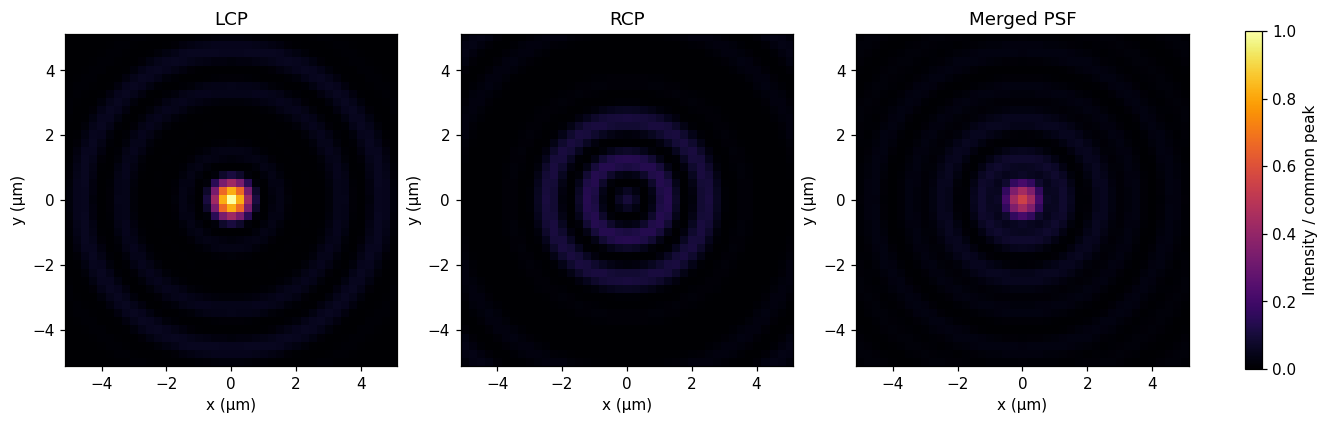

In [9]:
roi = np.flatnonzero(np.abs(x) <= 5 * um)
cut = slice(roi[0], roi[-1] + 1)
xy = []
for field in fields:
    propagated = angular_spectrum_method(np.pad(field, padding), focal_length, wavelength, dx)
    cropped = propagated[padding:padding+n, padding:padding+n]
    xy.append(np.abs(cropped[cut, cut])**2)
    del propagated, cropped
merged_xy = (xy[0] + xy[1]) / 2
scale = max(a.max() for a in xy)
roi_extent = [(x[roi[0]] - dx/2) / um, (x[roi[-1]] + dx/2) / um] * 2
fig, axes = plt.subplots(1, 3, figsize=(12, 3.7), constrained_layout=True)
for ax, intensity, title in zip(axes, [*xy, merged_xy], ['LCP', 'RCP', 'Merged PSF']):
    im = ax.imshow(intensity / scale, origin='lower', extent=roi_extent, cmap='inferno', vmin=0, vmax=1)
    ax.set(title=title, xlabel='x (µm)', ylabel='y (µm)')
fig.colorbar(im, ax=axes, label='Intensity / common peak')
fig.savefig(images / 'result.png', dpi=160)
plt.show()


## 4. Axial PSF and raw profiles
Sample z = 150–399.9 µm at 0.3 µm intervals (the selected axial window).
Retain only the central $y=0$ row using the same discrete ASM, reusing the spectrum
and advancing the propagation phase by a fixed step. Axial panels share one linear scale.


LCP: 1500 planes complete
RCP: 1500 planes complete


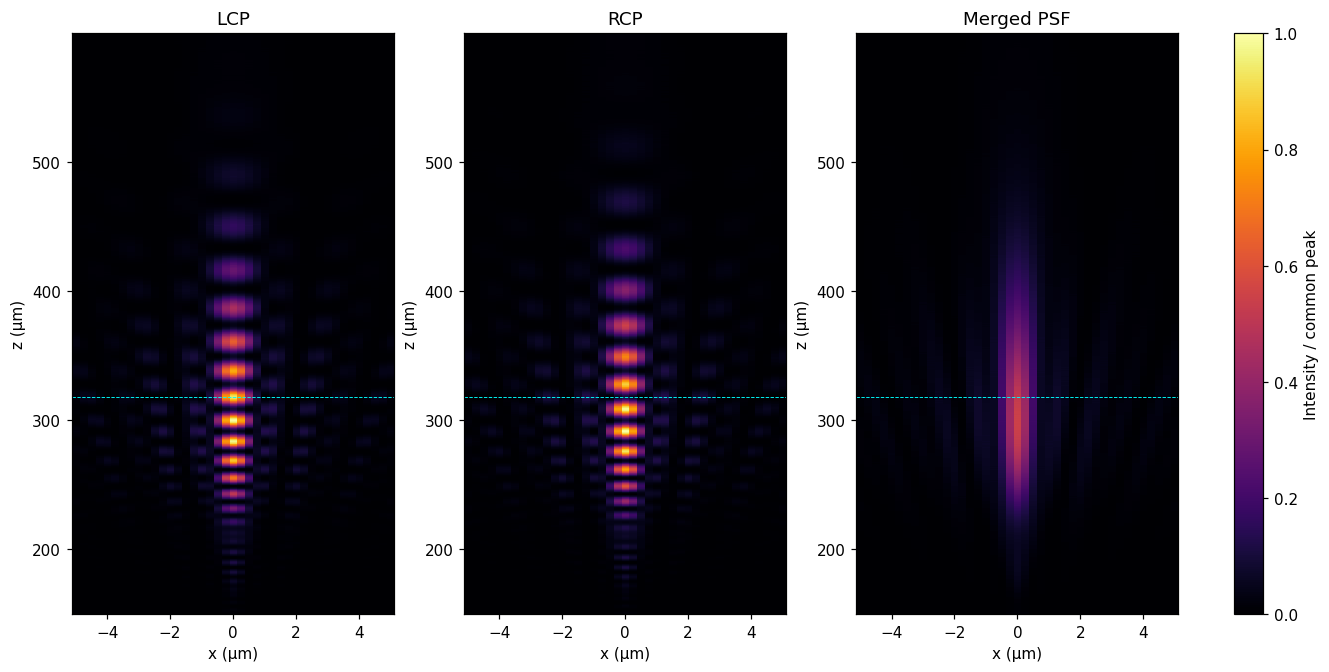

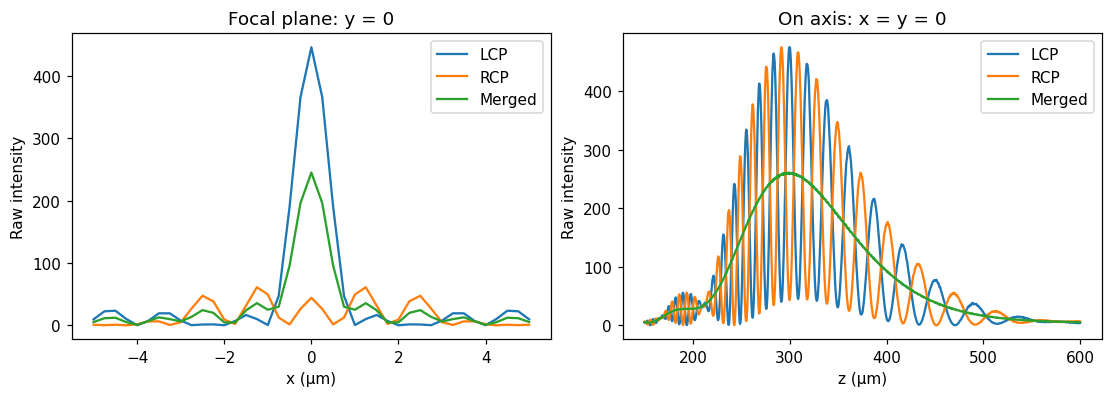

In [10]:
z = np.arange(150, 600, 0.3) * um
xz = []
for label, field in zip(['LCP', 'RCP'], fields):
    padded = np.pad(field, padding)
    xz.append(axial_intensity(padded, z, wavelength, dx, padding + roi))
    del padded
    print(f'{label}: {len(z)} planes complete')
    
merged_xz = (xz[0] + xz[1]) / 2
scale_xz = max(a.max() for a in xz)
dz = z[1] - z[0]
axial_extent = [*roi_extent[:2], (z[0]-dz/2)/um, (z[-1]+dz/2)/um]
fig, axes = plt.subplots(1, 3, figsize=(12, 6), constrained_layout=True)

for ax, intensity, title in zip(axes, [*xz, merged_xz], ['LCP', 'RCP', 'Merged PSF']):
    im = ax.imshow(intensity / scale_xz, origin='lower', extent=axial_extent,
                   aspect='auto', interpolation='nearest', cmap='inferno', vmin=0, vmax=1)
    ax.axhline(focal_length / um, color='cyan', lw=0.6, ls='--')
    ax.set(title=title, xlabel='x (µm)', ylabel='z (µm)')
fig.colorbar(im, ax=axes, label='Intensity / common peak')
fig.savefig(images / 'axial_psf.png', dpi=160)
plt.show()

center = np.flatnonzero(roi == n//2).item()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for label, focal, axial in zip(['LCP', 'RCP', 'Merged'], [*xy, merged_xy], [*xz, merged_xz]):
    axes[0].plot(x[roi] / um, focal[center], label=label)
    axes[1].plot(z / um, axial[:, center], label=label)
axes[0].set(xlabel='x (µm)', ylabel='Raw intensity', title='Focal plane: y = 0')
axes[1].set(xlabel='z (µm)', ylabel='Raw intensity', title='On axis: x = y = 0')
for ax in axes:
    ax.legend()
fig.savefig(images / 'line_profile.png', dpi=160)
plt.show()
